# Myanmar Rice Price Forecasting — Model Experiments

**Case study:** Pakokku market · Rice (low quality) · Retail · MMK/kg  
**Target:** the current month's observed price, forecast using information available before that month.

## Experiment protocol

- Keep missing monthly prices as `NaN`; do not manufacture training labels by interpolation.
- Construct lag and rolling features from prior months only.
- Compare full and compact feature sets on identical calendar months.
- Use a chronological 60/20/20 train/validation/test split.
- Select models using validation results. Use the test set only for the final, pre-specified evaluation.
- All metric tables are recalculated when the notebook runs. Previously discussed scores are not inserted as if freshly reproduced.

**Data path:** this notebook expects `../data/prices.csv` relative to its working directory. Change `DATA_PATH` if needed.

## 1. Environment and configuration

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/prices.csv")
TARGET_COMMODITY = "Rice (low quality)"
TARGET_UNIT = "KG"
TARGET_PRICE_TYPE = "Retail"
TARGET_CURRENCY = "MMK"
PAKOKKU_ID = 1664
RANDOM_STATE = 42

## 2. Load and standardize the raw dataset

In [8]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Check the notebook working directory and DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
df.columns = (
    df.columns.str.strip().str.lower()
    .str.replace(" ", "_", regex=False)
)

required_columns = {
    "date", "commodity", "market_id", "market",
    "unit", "pricetype", "currency", "price"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

rice_df = df[
    (df["commodity"] == TARGET_COMMODITY)
    & (df["unit"] == TARGET_UNIT)
    & (df["pricetype"] == TARGET_PRICE_TYPE)
    & (df["currency"] == TARGET_CURRENCY)
].dropna(subset=["date", "price"]).copy()

rice_df["month"] = rice_df["date"].dt.to_period("M")

monthly_rice = (
    rice_df.groupby(["market_id", "market", "month"])
    .agg(
        monthly_price=("price", "mean"),
        observation_count=("price", "count")
    )
    .reset_index()
    .sort_values(["market_id", "month"])
)

print("Filtered raw observations:", len(rice_df))
print("Monthly market-price rows:", len(monthly_rice))
print("Markets represented:", monthly_rice["market_id"].nunique())

Filtered raw observations: 10231
Monthly market-price rows: 10231
Markets represented: 298


## 3. Select Pakokku and restore its monthly calendar

Reindexing creates an explicit row for every month between the first and last observation. Missing prices remain `NaN`.

In [9]:
df_pakokku = (
    monthly_rice[monthly_rice["market_id"] == PAKOKKU_ID]
    .sort_values("month")
    .set_index("month")
    .copy()
)
if df_pakokku.empty:
    raise ValueError(f"No rice observations found for market ID {PAKOKKU_ID}.")

full_month_index = pd.period_range(
    start=df_pakokku.index.min(),
    end=df_pakokku.index.max(),
    freq="M"
)
df_pakokku = df_pakokku.reindex(full_month_index)
df_pakokku.index.name = "month"

print("First month:", df_pakokku.index.min())
print("Last month:", df_pakokku.index.max())
print("Calendar months:", len(df_pakokku))
print("Observed price months:", df_pakokku["monthly_price"].notna().sum())
print("Missing months:", df_pakokku["monthly_price"].isna().sum())
print("Coverage (%):", round(df_pakokku["monthly_price"].notna().mean() * 100, 1))
display(df_pakokku.loc[df_pakokku["monthly_price"].isna(),
                       ["monthly_price", "observation_count"]])

First month: 2014-01
Last month: 2026-09
Calendar months: 153
Observed price months: 146
Missing months: 7
Coverage (%): 95.4


,monthly_price,observation_count
month,,
2015-05,NaN,NaN
2015-06,NaN,NaN
2015-07,NaN,NaN
2019-05,NaN,NaN
2019-06,NaN,NaN
2020-02,NaN,NaN
2025-01,NaN,NaN


### 3.1 Consecutive runs of missing months

In [10]:
missing_periods = df_pakokku.index[df_pakokku["monthly_price"].isna()]
missing_runs = []
if len(missing_periods):
    run_start = previous = missing_periods[0]
    for period in missing_periods[1:]:
        if period == previous + 1:
            previous = period
        else:
            missing_runs.append((run_start, previous))
            run_start = previous = period
    missing_runs.append((run_start, previous))

missing_runs_df = pd.DataFrame([
    {
        "start_month": str(start),
        "end_month": str(end),
        "months_missing": (end - start).n + 1
    }
    for start, end in missing_runs
])
display(missing_runs_df)

,start_month,end_month,months_missing
0,2015-05,2015-07,3
1,2019-05,2019-06,2
2,2020-02,2020-02,1
3,2025-01,2025-01,1


## 4. Engineer full and compact lag features

The rolling means use `monthly_price.shift(1)`. Therefore, the target month's price is never included in its own rolling predictors.

In [11]:
# Full configuration: 12 lags + 3 rolling means
df_model = df_pakokku[["monthly_price"]].copy()
for lag in range(1, 13):
    df_model[f"lag_{lag}"] = df_model["monthly_price"].shift(lag)

history = df_model["monthly_price"].shift(1)
for window in [3, 6, 12]:
    df_model[f"rolling_mean_{window}"] = (
        history.rolling(window=window, min_periods=window).mean()
    )

full_feature_cols = [c for c in df_model.columns if c != "monthly_price"]
df_ready = df_model.dropna(subset=["monthly_price"] + full_feature_cols).copy()

# Compact configuration: 3 lags + 3-month rolling mean
df_compact = df_pakokku[["monthly_price"]].copy()
for lag in [1, 2, 3]:
    df_compact[f"lag_{lag}"] = df_compact["monthly_price"].shift(lag)

compact_history = df_compact["monthly_price"].shift(1)
df_compact["rolling_mean_3"] = (
    compact_history.rolling(window=3, min_periods=3).mean()
)
compact_feature_cols = [c for c in df_compact.columns if c != "monthly_price"]
df_compact_ready = df_compact.dropna(
    subset=["monthly_price"] + compact_feature_cols
).copy()

print("Original calendar months:", len(df_model))
print("Observed target months:", df_model["monthly_price"].notna().sum())
print("Full rows retained:", len(df_ready))
print("Compact rows retained:", len(df_compact_ready))
print("Full feature columns:", full_feature_cols)
print("Compact feature columns:", compact_feature_cols)

Original calendar months: 153
Observed target months: 146
Full rows retained: 91
Compact rows retained: 131
Full feature columns: ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12']
Compact feature columns: ['lag_1', 'lag_2', 'lag_3', 'rolling_mean_3']


## 5. Create common evaluation months and the 60/20/20 split

Both feature sets are restricted to the same intersection of usable months. This prevents a model from appearing better simply because it was evaluated on easier or different months.

In [12]:
common_months = df_ready.index.intersection(df_compact_ready.index).sort_values()
n = len(common_months)
if n < 3:
    raise ValueError("Not enough common observations for chronological splitting.")

train_end_idx = int(n * 0.60) - 1
val_end_idx = int(n * 0.80) - 1

train_end_date = common_months[train_end_idx]
val_start_date = common_months[train_end_idx + 1]
val_end_date = common_months[val_end_idx]
test_start_date = common_months[val_end_idx + 1]
test_end_date = common_months[-1]

df_full_eval = df_ready.loc[common_months].copy()
df_compact_eval = df_compact_ready.loc[common_months].copy()

assert df_full_eval.index.equals(df_compact_eval.index)
assert np.allclose(df_full_eval["monthly_price"], df_compact_eval["monthly_price"])

print("Common observations:", n)
print("TRAIN ends:", train_end_date)
print("VALIDATION:", val_start_date, "to", val_end_date)
print("TEST:", test_start_date, "to", test_end_date)

Common observations: 91
TRAIN ends: 2022-07
VALIDATION: 2022-08 to 2024-01
TEST: 2024-02 to 2026-09


In [13]:
def inspect_split(data, name):
    print(f"\n{name}")
    for label, subset in {
        "TRAIN": data.loc[:train_end_date],
        "VALIDATION": data.loc[val_start_date:val_end_date],
        "TEST": data.loc[test_start_date:test_end_date]
    }.items():
        print(f"{label}: {len(subset)} observations | "
              f"{subset.index.min()} to {subset.index.max()}")

inspect_split(df_full_eval, "FULL FEATURES")
inspect_split(df_compact_eval, "COMPACT FEATURES")


FULL FEATURES
TRAIN: 54 observations | 2015-01 to 2022-07
VALIDATION: 18 observations | 2022-08 to 2024-01
TEST: 19 observations | 2024-02 to 2026-09

COMPACT FEATURES
TRAIN: 54 observations | 2015-01 to 2022-07
VALIDATION: 18 observations | 2022-08 to 2024-01
TEST: 19 observations | 2024-02 to 2026-09


## 6. Plot the target and split boundaries

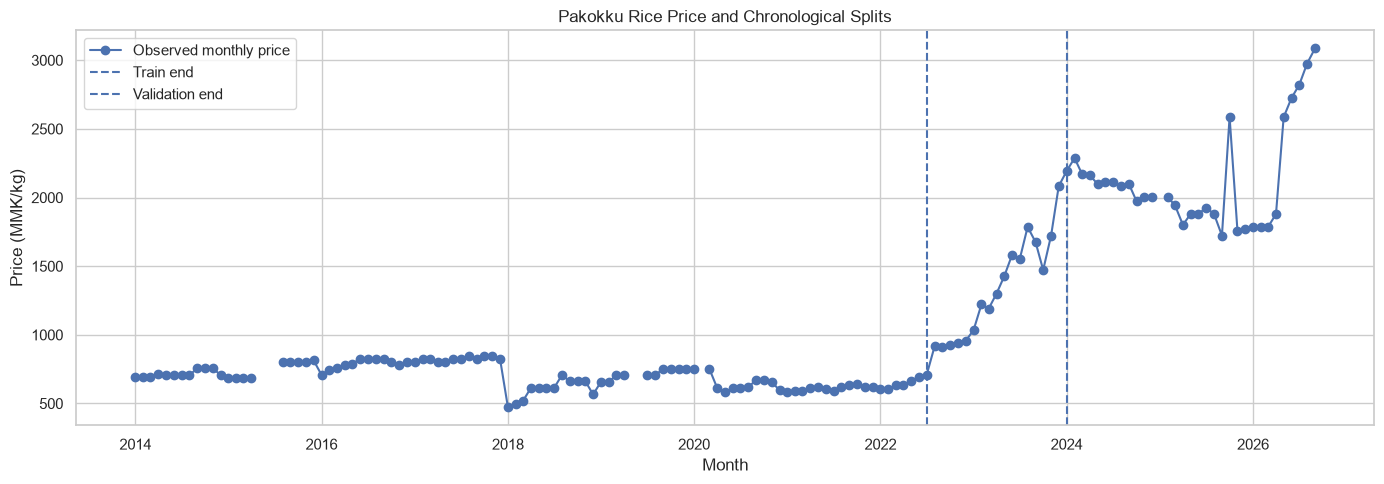

In [14]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_pakokku.index.to_timestamp(), df_pakokku["monthly_price"],
        marker="o", linewidth=1.5, label="Observed monthly price")
ax.axvline(train_end_date.to_timestamp(), linestyle="--", label="Train end")
ax.axvline(val_end_date.to_timestamp(), linestyle="--", label="Validation end")
ax.set(title="Pakokku Rice Price and Chronological Splits",
       xlabel="Month", ylabel="Price (MMK/kg)")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Forecasting baselines

The naive forecast carries forward the previous month's observed price. Seasonal naive uses the price 12 calendar months earlier. Moving-average baselines use historical rolling means. Each baseline reports the number of valid actual/predicted pairs.

In [15]:
def regression_metrics(actual, predicted):
    actual = pd.Series(actual)
    predicted = pd.Series(predicted, index=actual.index)
    valid = actual.notna() & predicted.notna()
    a, p = actual.loc[valid], predicted.loc[valid]
    return {
        "observations": int(valid.sum()),
        "MAE": mean_absolute_error(a, p),
        "RMSE": np.sqrt(mean_squared_error(a, p))
    }

validation_full = df_full_eval.loc[val_start_date:val_end_date]
baseline_candidates = {
    "Naive (lag 1)": "lag_1",
    "Seasonal naive (lag 12)": "lag_12",
    "Moving average (3)": "rolling_mean_3",
    "Moving average (6)": "rolling_mean_6",
    "Moving average (12)": "rolling_mean_12"
}

baseline_rows = []
for name, col in baseline_candidates.items():
    baseline_rows.append({
        "model": name,
        "configuration": "Full baseline",
        **regression_metrics(validation_full["monthly_price"], validation_full[col])
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values("RMSE")
display(baseline_results.round(2))

,model,configuration,observations,MAE,RMSE
0,Naive (lag 1),Full baseline,18,124.91,158.57
2,Moving average (3),Full baseline,18,175.58,214.24
3,Moving average (6),Full baseline,18,248.44,274.29
4,Moving average (12),Full baseline,18,394.38,424.77
1,Seasonal naive (lag 12),Full baseline,18,639.84,696.06


## 8. Linear Regression and Ridge Regression

Standardization is fitted inside a pipeline, using training data only.

In [16]:
def evaluate_model(data, estimator, model_name, config_name):
    train = data.loc[:train_end_date]
    val = data.loc[val_start_date:val_end_date]
    X_train = train.drop(columns=["monthly_price"])
    y_train = train["monthly_price"]
    X_val = val.drop(columns=["monthly_price"])
    y_val = val["monthly_price"]

    fitted = clone(estimator)
    fitted.fit(X_train, y_train)
    pred = pd.Series(fitted.predict(X_val), index=y_val.index)

    return {
        "model": model_name,
        "configuration": config_name,
        **regression_metrics(y_val, pred)
    }, fitted, pred

datasets = {"Full": df_full_eval, "Compact": df_compact_eval}
linear_models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (alpha=1)": make_pipeline(StandardScaler(), Ridge(alpha=1.0))
}

linear_rows, linear_fitted, linear_preds = [], {}, {}
for config, data in datasets.items():
    for name, estimator in linear_models.items():
        row, fitted, pred = evaluate_model(data, estimator, name, config)
        linear_rows.append(row)
        linear_fitted[(config, name)] = fitted
        linear_preds[(config, name)] = pred

linear_results = pd.DataFrame(linear_rows).sort_values("RMSE")
display(linear_results.round(2))

,model,configuration,observations,MAE,RMSE
0,Linear Regression,Full,18,190.71,235.58
1,Ridge (alpha=1),Full,18,200.26,244.42
2,Linear Regression,Compact,18,198.14,249.99
3,Ridge (alpha=1),Compact,18,205.64,257.38


### 8.1 Actual vs naive and full-feature Linear Regression

,Actual,Naive (lag 1),Linear Regression,Naive absolute error,Linear absolute error
month,,,,,
2022-08,915.00,708.00,704.57,207.00,210.43
2022-09,910.00,915.00,890.14,5.00,19.86
2022-10,924.00,910.00,868.72,14.00,55.28
2022-11,939.00,924.00,851.94,15.00,87.06
2022-12,956.00,939.00,904.96,17.00,51.04
2023-01,1034.00,956.00,908.10,78.00,125.90
2023-02,1222.00,1034.00,1003.68,188.00,218.32
2023-03,1190.00,1222.00,1098.63,32.00,91.37
2023-04,1300.00,1190.00,1128.97,110.00,171.03


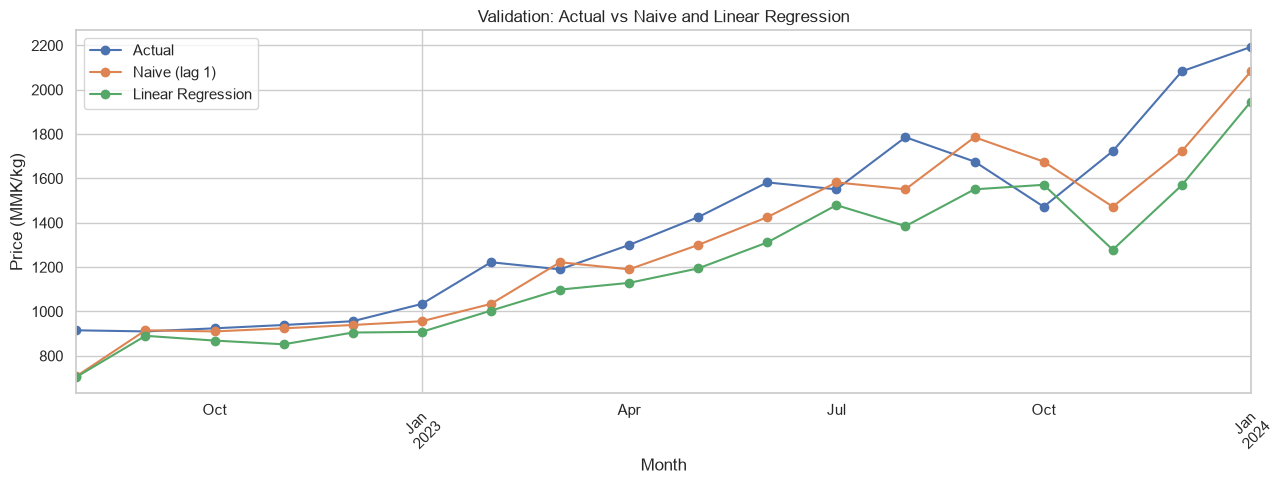

In [17]:
val = df_full_eval.loc[val_start_date:val_end_date]
comparison = pd.DataFrame({
    "Actual": val["monthly_price"],
    "Naive (lag 1)": val["lag_1"],
    "Linear Regression": linear_preds[("Full", "Linear Regression")]
})
comparison["Naive absolute error"] = (
    comparison["Actual"] - comparison["Naive (lag 1)"]
).abs()
comparison["Linear absolute error"] = (
    comparison["Actual"] - comparison["Linear Regression"]
).abs()
display(comparison.round(2))

ax = comparison[["Actual", "Naive (lag 1)", "Linear Regression"]].plot(
    figsize=(13, 5), marker="o"
)
ax.set(title="Validation: Actual vs Naive and Linear Regression",
       ylabel="Price (MMK/kg)", xlabel="Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Random Forest and XGBoost

Tree models do not require feature standardization. The supplied hyperparameters are retained for this initial comparison.

In [18]:
tree_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=5, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=3,
        subsample=0.8, colsample_bytree=0.8,
        random_state=RANDOM_STATE, objective="reg:squarederror",
        n_jobs=-1
    )
}

tree_rows, tree_fitted, tree_preds = [], {}, {}
for config, data in datasets.items():
    for name, estimator in tree_models.items():
        row, fitted, pred = evaluate_model(data, estimator, name, config)
        tree_rows.append(row)
        tree_fitted[(config, name)] = fitted
        tree_preds[(config, name)] = pred

tree_results = pd.DataFrame(tree_rows).sort_values("RMSE")
display(tree_results.round(2))

,model,configuration,observations,MAE,RMSE
0,Random Forest,Full,18,649.21,760.26
2,Random Forest,Compact,18,652.45,765.36
3,XGBoost,Compact,18,661.10,776.82
1,XGBoost,Full,18,801.25,939.19


## 10. Validation leaderboard

The naive row is shown once because both feature configurations share the same evaluation months and lag-1 baseline.

In [19]:
naive_row = baseline_results.loc[
    baseline_results["model"] == "Naive (lag 1)"
].iloc[[0]].copy()
leaderboard = pd.concat(
    [naive_row, linear_results, tree_results],
    ignore_index=True,
    sort=False
).sort_values("RMSE")
display(leaderboard.round(2))

,model,configuration,observations,MAE,RMSE
0,Naive (lag 1),Full baseline,18,124.91,158.57
1,Linear Regression,Full,18,190.71,235.58
2,Ridge (alpha=1),Full,18,200.26,244.42
3,Linear Regression,Compact,18,198.14,249.99
4,Ridge (alpha=1),Compact,18,205.64,257.38
5,Random Forest,Full,18,649.21,760.26
6,Random Forest,Compact,18,652.45,765.36
7,XGBoost,Compact,18,661.10,776.82
8,XGBoost,Full,18,801.25,939.19


## 11. Tree-depth sensitivity experiment

In [20]:
depth_thresholds = [2, 3, 5, 8, None]
depth_rows = []

for config, data in datasets.items():
    for depth in depth_thresholds:
        label = "Unlimited" if depth is None else str(depth)

        rf = RandomForestRegressor(
            n_estimators=200, max_depth=depth,
            random_state=RANDOM_STATE, n_jobs=-1
        )
        row, _, _ = evaluate_model(data, rf, "Random Forest", config)
        row["max_depth_threshold"] = label
        depth_rows.append(row)

        # The original experiment used depth 10 as the finite approximation
        # for the XGBoost "Unlimited" comparison.
        xgb_depth = 10 if depth is None else depth
        xgb = XGBRegressor(
            n_estimators=200, learning_rate=0.05, max_depth=xgb_depth,
            subsample=0.8, colsample_bytree=0.8,
            random_state=RANDOM_STATE, objective="reg:squarederror",
            n_jobs=-1
        )
        row, _, _ = evaluate_model(data, xgb, "XGBoost", config)
        row["max_depth_threshold"] = label
        depth_rows.append(row)

depth_comparison = pd.DataFrame(depth_rows).sort_values(
    ["configuration", "RMSE"]
)
display(depth_comparison.round(2))

best_depth_per_model = (
    depth_comparison.sort_values("RMSE")
    .groupby(["configuration", "model"], as_index=False)
    .first()
)
display(best_depth_per_model.round(2))

,model,configuration,observations,MAE,RMSE,max_depth_threshold
13,XGBoost,Compact,18,661.10,776.82,3
15,XGBoost,Compact,18,662.91,777.88,5
17,XGBoost,Compact,18,663.91,778.49,8
19,XGBoost,Compact,18,665.06,779.73,Unlimited
11,XGBoost,Compact,18,663.78,780.07,2
10,Random Forest,Compact,18,688.01,799.67,2
18,Random Forest,Compact,18,688.28,801.09,Unlimited
16,Random Forest,Compact,18,692.84,805.63,8
12,Random Forest,Compact,18,694.29,807.37,3
14,Random Forest,Compact,18,697.59,810.30,5


,configuration,model,observations,MAE,RMSE,max_depth_threshold
0,Compact,Random Forest,18,688.01,799.67,2
1,Compact,XGBoost,18,661.10,776.82,3
2,Full,Random Forest,18,713.76,835.65,3
3,Full,XGBoost,18,788.43,920.37,2


## 12. Differenced-target experiment

The target is the absolute month-to-month price change, `monthly_price - lag_1`. The predicted change is added to `lag_1` to reconstruct the price. This implementation also corrects the earlier rolling-column prefix mismatch (`rolling_mean_`, not `roll_mean_`).

In [21]:
def make_differenced_features(data):
    transformed = data.copy()
    y_diff = transformed["monthly_price"] - transformed["lag_1"]
    price_cols = [
        c for c in transformed.columns
        if c.startswith(("lag_", "rolling_mean_")) and c != "lag_1"
    ]
    for col in price_cols:
        transformed[f"{col}_diff"] = transformed[col] - transformed["lag_1"]
    X_diff = transformed.drop(columns=["monthly_price", "lag_1"] + price_cols)
    return X_diff, y_diff

def evaluate_transformed_target(data, estimator, model_name, config_name, mode):
    if mode == "difference":
        X_transformed, y_transformed = make_differenced_features(data)
    elif mode == "percentage":
        X_transformed, y_transformed = make_percentage_features(data)
    else:
        raise ValueError("mode must be 'difference' or 'percentage'")

    train_mask = X_transformed.index <= train_end_date
    val_mask = (
        (X_transformed.index >= val_start_date)
        & (X_transformed.index <= val_end_date)
    )
    X_train = X_transformed.loc[train_mask]
    y_train = y_transformed.loc[train_mask]
    X_val = X_transformed.loc[val_mask]
    val = data.loc[val_mask]
    lag1 = val["lag_1"]

    # Exclude rows where transformed features/targets are unavailable.
    train_ok = X_train.notna().all(axis=1) & y_train.notna()
    val_ok = X_val.notna().all(axis=1) & lag1.notna()
    X_train, y_train = X_train.loc[train_ok], y_train.loc[train_ok]
    X_val = X_val.loc[val_ok]
    val = val.loc[val_ok]
    lag1 = lag1.loc[val_ok]

    fitted = clone(estimator)
    fitted.fit(X_train, y_train)
    predicted_target = fitted.predict(X_val)

    if mode == "difference":
        predicted_price = lag1 + predicted_target
        label = "Differenced"
    else:
        predicted_price = lag1 * (1 + predicted_target)
        label = "Percentage return"

    predicted_price = pd.Series(predicted_price, index=val.index)
    return {
        "model": f"{model_name} ({label})",
        "configuration": config_name,
        **regression_metrics(val["monthly_price"], predicted_price)
    }, predicted_price

diff_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=4, min_samples_leaf=3,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=100, learning_rate=0.03, max_depth=2,
        subsample=0.8, random_state=RANDOM_STATE,
        objective="reg:squarederror", n_jobs=-1
    )
}

diff_rows, diff_preds = [], {}
for config, data in datasets.items():
    for name, estimator in diff_models.items():
        row, pred = evaluate_transformed_target(
            data, estimator, name, config, "difference"
        )
        diff_rows.append(row)
        diff_preds[(config, name)] = pred

diff_results = pd.DataFrame(diff_rows).sort_values("RMSE")
display(diff_results.round(2))

,model,configuration,observations,MAE,RMSE
2,Random Forest (Differenced),Compact,18,123.53,158.95
3,XGBoost (Differenced),Compact,18,123.72,159.42
0,Random Forest (Differenced),Full,18,133.46,168.98
1,XGBoost (Differenced),Full,18,141.12,184.39


## 13. Percentage-return target experiment

The target is the relative change from the previous month's price. Price lags and rolling means are expressed as relative differences from `lag_1`, then predictions are reconstructed as `lag_1 * (1 + predicted_return)`.

In [22]:
def make_percentage_features(data):
    transformed = data.copy()
    y_pct = (
        transformed["monthly_price"] - transformed["lag_1"]
    ) / transformed["lag_1"]

    price_cols = [
        c for c in transformed.columns
        if c.startswith(("lag_", "rolling_mean_")) and c != "lag_1"
    ]
    for col in price_cols:
        transformed[f"{col}_pct"] = (
            transformed[col] - transformed["lag_1"]
        ) / transformed["lag_1"]

    X_pct = transformed.drop(
        columns=["monthly_price", "lag_1"] + price_cols
    )
    return X_pct, y_pct

pct_models = {
    "Random Forest (Pct)": RandomForestRegressor(
        n_estimators=200, max_depth=4, min_samples_leaf=3,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost (Pct)": XGBRegressor(
        n_estimators=100, learning_rate=0.03, max_depth=2,
        subsample=0.8, random_state=RANDOM_STATE,
        objective="reg:squarederror", n_jobs=-1
    ),
    "Ridge (Pct)": make_pipeline(StandardScaler(), Ridge(alpha=1.0))
}

pct_rows, pct_preds = [], {}
for name, estimator in pct_models.items():
    row, pred = evaluate_transformed_target(
        df_full_eval, estimator, name, "Full", "percentage"
    )
    pct_rows.append(row)
    pct_preds[name] = pred

pct_results = pd.DataFrame(pct_rows).sort_values("RMSE")
display(pct_results.round(2))

,model,configuration,observations,MAE,RMSE
0,Random Forest (Pct) (Percentage return),Full,18,134.70,174.32
2,Ridge (Pct) (Percentage return),Full,18,142.59,181.17
1,XGBoost (Pct) (Percentage return),Full,18,146.71,200.14


## 14. Macro and regime features

The original code used `.bfill()` for early volatility and momentum values. Backfilling can copy later information into earlier rows, so this refined version leaves unavailable early values missing and excludes those rows from model fitting/evaluation. All macro features are derived from `lag_1`, which is historical relative to the target month.

In [23]:
def make_macro_features(data):
    out = data.copy()
    X_pct, y_pct = make_percentage_features(out)

    # Monotonic time index
    X_pct["time_idx"] = np.arange(len(out))

    # Historical price regime relative to expanding mean
    expanding_mean = out["lag_1"].expanding(min_periods=1).mean()
    X_pct["regime_ratio_to_hist"] = out["lag_1"] / expanding_mean

    # Historical monthly return volatility; no backfill
    hist_returns = out["lag_1"].pct_change()
    X_pct["expanding_return_vol"] = (
        hist_returns.expanding(min_periods=2).std()
    )

    # Three-month momentum based on information available at t-1
    X_pct["momentum_3m_pct"] = out["lag_1"].pct_change(periods=3)

    return X_pct, y_pct

macro_models = {
    "Ridge (Pct + Macro)": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "Random Forest (Pct + Macro)": RandomForestRegressor(
        n_estimators=200, max_depth=4, min_samples_leaf=3,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost (Pct + Macro)": XGBRegressor(
        n_estimators=100, learning_rate=0.03, max_depth=2,
        subsample=0.8, random_state=RANDOM_STATE,
        objective="reg:squarederror", n_jobs=-1
    )
}

X_macro, y_macro = make_macro_features(df_full_eval)
macro_train_mask = X_macro.index <= train_end_date
macro_val_mask = (
    (X_macro.index >= val_start_date)
    & (X_macro.index <= val_end_date)
)

X_train = X_macro.loc[macro_train_mask]
y_train = y_macro.loc[macro_train_mask]
X_val = X_macro.loc[macro_val_mask]
val_actual = df_full_eval.loc[macro_val_mask, "monthly_price"]
val_lag1 = df_full_eval.loc[macro_val_mask, "lag_1"]

train_ok = X_train.notna().all(axis=1) & y_train.notna()
val_ok = X_val.notna().all(axis=1) & val_actual.notna() & val_lag1.notna()
X_train, y_train = X_train.loc[train_ok], y_train.loc[train_ok]
X_val = X_val.loc[val_ok]
val_actual, val_lag1 = val_actual.loc[val_ok], val_lag1.loc[val_ok]

macro_rows, macro_preds = [], {}
for name, estimator in macro_models.items():
    fitted = clone(estimator)
    fitted.fit(X_train, y_train)
    pred_pct = fitted.predict(X_val)
    pred_price = pd.Series(
        val_lag1.to_numpy() * (1 + pred_pct),
        index=val_actual.index
    )
    macro_preds[name] = pred_price
    macro_rows.append({
        "model": name,
        "configuration": "Full",
        **regression_metrics(val_actual, pred_price)
    })

macro_results = pd.DataFrame(macro_rows).sort_values("RMSE")
display(macro_results.round(2))

,model,configuration,observations,MAE,RMSE
1,Random Forest (Pct + Macro),Full,18,135.34,173.08
2,XGBoost (Pct + Macro),Full,18,141.01,177.98
0,Ridge (Pct + Macro),Full,18,198.82,240.16


## 15. Walk-forward validation

The supplied workflow compared four retraining strategies:

- **Static:** fit once through the end of training (2022-07), then forecast the validation period without retraining.
- **Expanding:** refit each month using all observations available before that month.
- **Sliding 36 months:** refit using only the latest 36 prior observations.
- **Sliding 24 months:** refit using only the latest 24 prior observations.

This is a one-step-ahead setup: each validation month may use the actual observed price from the previous month, as encoded in its lag features.

In [24]:
X_all, y_pct_all = make_percentage_features(df_full_eval)
y_actual_all = df_full_eval["monthly_price"]
lag1_all = df_full_eval["lag_1"]

val_positions = np.where(
    (X_all.index >= val_start_date) & (X_all.index <= val_end_date)
)[0]

def run_walk_forward(estimator, window_type="expanding", window_size=None):
    predictions = []
    if window_type == "static":
        train_mask = X_all.index <= train_end_date
        X_train = X_all.loc[train_mask]
        y_train = y_pct_all.loc[train_mask]
        ok = X_train.notna().all(axis=1) & y_train.notna()
        fitted = clone(estimator).fit(X_train.loc[ok], y_train.loc[ok])
        pred_pct = fitted.predict(X_all.iloc[val_positions])
        predictions = (
            lag1_all.iloc[val_positions].to_numpy() * (1 + pred_pct)
        )
    else:
        for pos in val_positions:
            start = 0 if window_type == "expanding" else max(0, pos - window_size)
            X_train = X_all.iloc[start:pos]
            y_train = y_pct_all.iloc[start:pos]
            ok = X_train.notna().all(axis=1) & y_train.notna()
            X_train, y_train = X_train.loc[ok], y_train.loc[ok]
            fitted = clone(estimator).fit(X_train, y_train)
            pred_pct = fitted.predict(X_all.iloc[[pos]])[0]
            predictions.append(lag1_all.iloc[pos] * (1 + pred_pct))

    return pd.Series(predictions, index=X_all.index[val_positions])

walk_models = {
    "Ridge (Pct)": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "Random Forest (Pct)": RandomForestRegressor(
        n_estimators=200, max_depth=4, min_samples_leaf=3,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost (Pct)": XGBRegressor(
        n_estimators=100, learning_rate=0.03, max_depth=2,
        subsample=0.8, random_state=RANDOM_STATE,
        objective="reg:squarederror", n_jobs=-1
    )
}

window_configs = [
    ("Static (frozen)", "static", None),
    ("Expanding walk-forward", "expanding", None),
    ("Sliding walk-forward (36m)", "sliding", 36),
    ("Sliding walk-forward (24m)", "sliding", 24)
]

y_val_actual = y_actual_all.iloc[val_positions]
lag1_val = lag1_all.iloc[val_positions]
walk_rows, walk_preds = [], {}

walk_rows.append({
    "model": "Naive (lag 1)",
    "training_strategy": "One-step carry forward",
    **regression_metrics(y_val_actual, lag1_val)
})

for model_name, estimator in walk_models.items():
    for label, window_type, window_size in window_configs:
        pred = run_walk_forward(estimator, window_type, window_size)
        walk_preds[(model_name, label)] = pred
        walk_rows.append({
            "model": model_name,
            "training_strategy": label,
            **regression_metrics(y_val_actual, pred)
        })

walk_results = pd.DataFrame(walk_rows).sort_values("RMSE")
display(walk_results.round(2))

,model,training_strategy,observations,MAE,RMSE
11,XGBoost (Pct),Sliding walk-forward (36m),18,116.39,138.19
7,Random Forest (Pct),Sliding walk-forward (36m),18,115.40,145.48
8,Random Forest (Pct),Sliding walk-forward (24m),18,118.00,146.03
12,XGBoost (Pct),Sliding walk-forward (24m),18,121.80,148.99
3,Ridge (Pct),Sliding walk-forward (36m),18,113.07,150.25
10,XGBoost (Pct),Expanding walk-forward,18,124.23,151.95
2,Ridge (Pct),Expanding walk-forward,18,123.90,152.11
4,Ridge (Pct),Sliding walk-forward (24m),18,124.60,154.56
6,Random Forest (Pct),Expanding walk-forward,18,127.05,155.09
0,Naive (lag 1),One-step carry forward,18,124.91,158.57


### 15.1 Plot selected walk-forward forecasts

The best expanding and best sliding entries are selected by validation RMSE for visualization only. This does not change the pre-specified final test candidate.

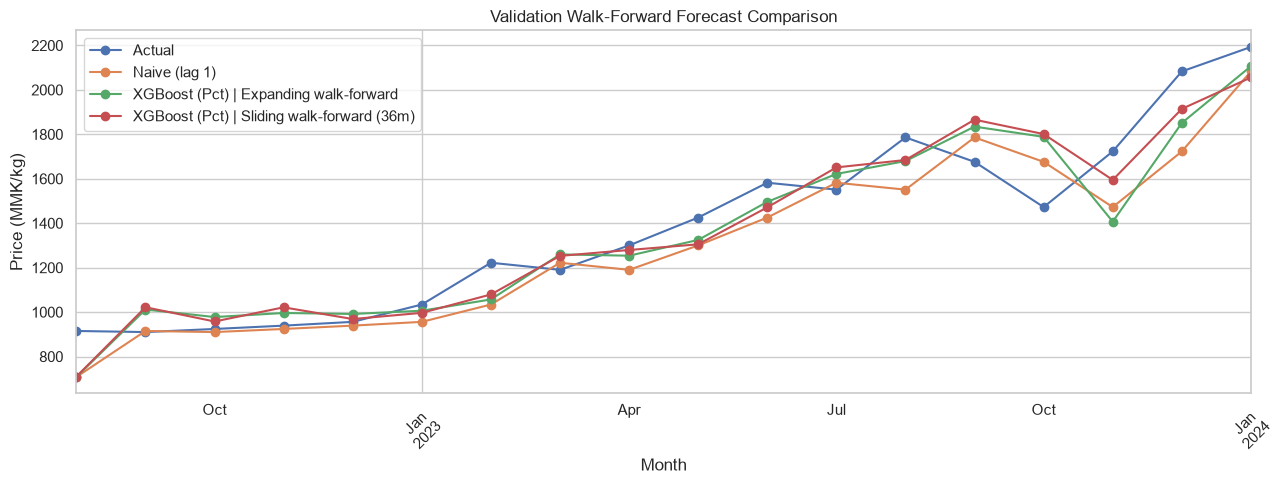

In [25]:
expanding_rows = walk_results[
    walk_results["training_strategy"] == "Expanding walk-forward"
]
sliding_rows = walk_results[
    walk_results["training_strategy"].str.startswith("Sliding")
]

if len(expanding_rows) and len(sliding_rows):
    best_expanding = expanding_rows.sort_values("RMSE").iloc[0]
    best_sliding = sliding_rows.sort_values("RMSE").iloc[0]

    exp_key = (best_expanding["model"], best_expanding["training_strategy"])
    slide_key = (best_sliding["model"], best_sliding["training_strategy"])

    plot_df = pd.DataFrame({
        "Actual": y_val_actual,
        "Naive (lag 1)": lag1_val,
        f"{exp_key[0]} | {exp_key[1]}": walk_preds[exp_key],
        f"{slide_key[0]} | {slide_key[1]}": walk_preds[slide_key]
    })
    ax = plot_df.plot(figsize=(13, 5), marker="o")
    ax.set(title="Validation Walk-Forward Forecast Comparison",
           ylabel="Price (MMK/kg)", xlabel="Month")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 16. Final holdout test: XGBoost percentage-return, 36-month sliding window

This reproduces the final test candidate explicitly specified in the supplied code. It is **not automatically the validation winner**. Confirm that this candidate was selected using validation results before interpreting the test score as an unbiased final estimate.

The procedure refits at each test month using the preceding 36 available rows and predicts one month ahead. It uses the actual previous month's price (`lag_1`) to reconstruct the forecast, so this is rolling one-step-ahead evaluation rather than a single multi-month forecast issued at the start of the test period.

In [26]:
test_positions = np.where(
    (X_all.index >= test_start_date) & (X_all.index <= test_end_date)
)[0]

y_test_actual = y_actual_all.iloc[test_positions]
lag1_test = lag1_all.iloc[test_positions]

final_candidate = XGBRegressor(
    n_estimators=100, learning_rate=0.03, max_depth=2,
    subsample=0.8, random_state=RANDOM_STATE,
    objective="reg:squarederror", n_jobs=-1
)
window_size = 36
test_predictions = []

for pos in test_positions:
    start = max(0, pos - window_size)
    X_train = X_all.iloc[start:pos]
    y_train = y_pct_all.iloc[start:pos]
    ok = X_train.notna().all(axis=1) & y_train.notna()
    X_train, y_train = X_train.loc[ok], y_train.loc[ok]

    fitted = clone(final_candidate).fit(X_train, y_train)
    pred_pct = fitted.predict(X_all.iloc[[pos]])[0]
    test_predictions.append(lag1_all.iloc[pos] * (1 + pred_pct))

test_pred_series = pd.Series(test_predictions, index=y_test_actual.index)

test_summary = pd.DataFrame([
    {
        "model": "XGBoost percentage-return (36m sliding)",
        **regression_metrics(y_test_actual, test_pred_series)
    },
    {
        "model": "Naive (lag 1)",
        **regression_metrics(y_test_actual, lag1_test)
    }
])
display(test_summary.round(2))

,model,observations,MAE,RMSE
0,XGBoost percentage-return (36m sliding),19,122.32,189.82
1,Naive (lag 1),19,94.84,179.92


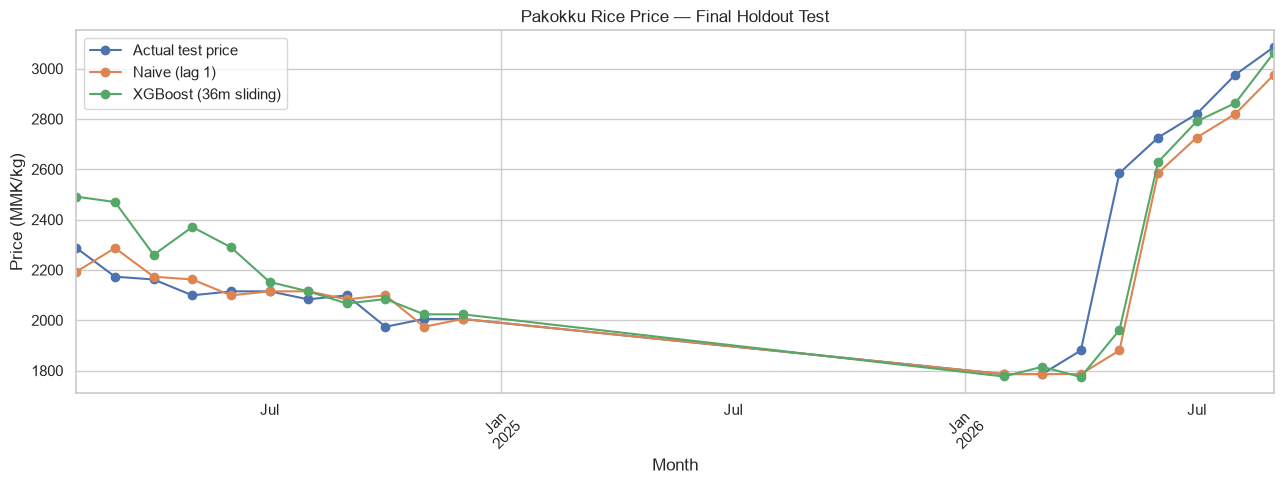

In [27]:
test_plot = pd.DataFrame({
    "Actual test price": y_test_actual,
    "Naive (lag 1)": lag1_test,
    "XGBoost (36m sliding)": test_pred_series
})
ax = test_plot.plot(figsize=(13, 5), marker="o")
ax.set(title="Pakokku Rice Price — Final Holdout Test",
       ylabel="Price (MMK/kg)", xlabel="Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 17. Error-tolerance analysis

This reports the percentage of forecasts whose absolute error falls within selected MMK/kg tolerances. It supplements MAE and RMSE; it does not replace them.

In [28]:
def tolerance_metrics(actual, predicted, thresholds=(50, 100, 150, 200)):
    actual = pd.Series(actual)
    predicted = pd.Series(predicted, index=actual.index)
    valid = actual.notna() & predicted.notna()
    error = (actual.loc[valid] - predicted.loc[valid]).abs()
    result = {
        "observations": len(error),
        "MAE": error.mean(),
        "RMSE": np.sqrt(np.mean(error ** 2))
    }
    for threshold in thresholds:
        result[f"Within ±{threshold} MMK (%)"] = (
            (error <= threshold).mean() * 100
        )
    return result

validation_tolerance = pd.DataFrame([
    {"model": "Naive", **tolerance_metrics(y_val_actual, lag1_val)},
    {"model": "XGBoost (Pct, static)", **tolerance_metrics(
        y_val_actual,
        pd.Series(
            lag1_val.to_numpy() * (
                1 + clone(walk_models["XGBoost (Pct)"])
                .fit(
                    X_all.loc[X_all.index <= train_end_date],
                    y_pct_all.loc[y_pct_all.index <= train_end_date]
                )
                .predict(X_all.iloc[val_positions])
            )
        , index=y_val_actual.index
        )
    )}
])
display(validation_tolerance.round(2))

,model,observations,MAE,RMSE,Within ±50 MMK (%),Within ±100 MMK (%),Within ±150 MMK (%),Within ±200 MMK (%)
0,Naive,18,124.91,158.57,33.33,38.89,61.11,72.22
1,"XGBoost (Pct, static)",18,146.71,200.14,33.33,44.44,55.56,72.22
